# 3) Logistic Regression : scikit-learn VS neural networks

**Logistic regression**

*The logistic regression is a machine learning classifier for multiclass classification.*


**Binary classification**: it employs the *sigmoid* function
$$
\sigma(x)=\dfrac{1}{1+e^{-x}},
$$
mapping data into the interval $[0, 1]$. Because of the specific shape of this function around $0$, data are naturally classified as $0$ or $1$.

>It predicts the probability of classifying as 1 the input $x$ though the sigmoid function:
>
>$$
>\hat{y} = P(y=1\mid\mathbf{x})=\sigma(\mathbf{x}\cdot \mathbf{W} +b)
>=\frac{1}{1+e^{-(\mathbf{x}\cdot \mathbf{W} +b)}}.
>$$
>We want to learn the parameters/weights W and the bias term b,
>by minimizing the *binary cross-entropy loss*:
>$$
>L(y, \hat{y})=-\sum_{i=1}^{n}\left[y_i\log(\hat{y_i})+(1-y_i)\log(1-\hat{y_i})\right],
>\quad p_i=P(y_i=1\mid\mathbf{x}_i),
>$$
>where $y_i$ are the labels and $\hat{y_i}$ are the predicted values.

**Multiclass classification**: it employs the *softmax* function
$$
\sigma(z_0,\dots,z_{n})=\dfrac{1}{\sum_{i=0}^{n} e^{z_i}}\cdot \left(e^{z_0},\dots,e^{z_{n}}\right) \in\mathbb{R}^{n+1}
$$
to classify data into $n+1$ classes. For 2 classes, the softmax is approximated by the sigmoid.

>It predicts the probabilities of classifying the input $\mathbf{x}\in\mathbb{R}^{k}$ in classes $[|0,n|]$, through the softmax function
>
>$$
>p = P(y\in[|0,n|]\mid\mathbf{x})=\sigma(\mathbf{x}\cdot \mathbf{W} +b).
>$$
>We want to learn the parameters/weights $\mathbf{W}\in\mathbb{R}^{k \times (n+1)}$ and the bias term $b\in\mathbb{R}^{n+1}$,
>by minimizing the *multi cross-entropy loss*:
>$$
>L(y, \hat{y})=-\sum_{i=0}^{n} y_i \, log(\hat{y_i}),
>$$
>where $y_i$ are the labels and $\hat{y_i}$ are the predicted values.

Often, to simplify we consider the softmax $\sigma(x\cdot \mathbf{W}')$ where $\mathbf{W}'=(\mathbf{W}, b) \in \mathbb{R}^{(k+1)\times (n+1)}$.

Rmk) The logistic regression model offers an alternative to the old *Perceptron* model, given by the $sign$ function
$$
sign(x) = \begin{cases} 1 \quad &if \quad  x\geq 0 \\
                        0 \quad &if \quad x< 0 \\
          \end{cases}.
$$

Perceptron was the very first machine learning model for binary classification, then surpassed by the logistic regression. Unlike the sigmoid function, the sign is not continuous and neither differentiable in $0$, which causes problems if we need to compute the gradient during the optimization phase and loss of information.

In [4]:
import numpy

In [7]:
# sklearn for logistic regression
from sklearn.model_selection import train_test_split                 #classic machine learning, scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# plot images
from matplotlib import pyplot as plt

**Import dataset MNIST from torchvision.datasets** :

A dataset of images of numbers.

In [16]:
from torchvision.datasets import MNIST

data = MNIST('mnist', download=True)

images, labels = data.data, data.targets     #{x_i, y_i}_i : dataset
                                             # torch.Size([60000, 28, 28]) for images

X = images.reshape(60000, 784)               # read the x_i as matrices of dim 60000 x (28*28)

#SPLIT DATASET INTO TRAINING + VALIDATION (unseen data for tuning the model)
X_train, X_valid, y_train, y_valid = train_test_split(X, labels, test_size=0.1, random_state=0)          #10% for validation


### How is MNIST done

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

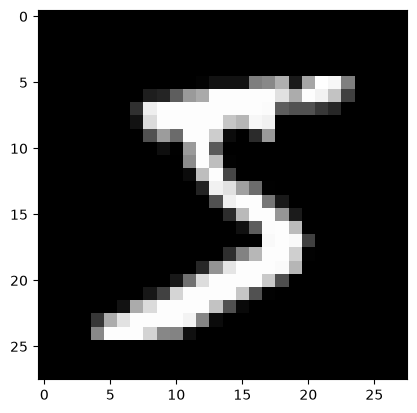

In [21]:
print(images[0])  # matrix

plt.imshow(images[0], cmap='gray')  # show matrix as image in gray

print(labels[0])  # labels of numbers

## Scikit-learn, classic machine learning approach

> A classic (supervised) machine learning approach consists in the following phases, run for an epoch:
> 1) Model definition
> 2) Training on training set
> 3) Prediction of labels on validation set
> 4) Evaluation through a metrics

**Epoch**: one complete pass through the entire training dataset / one run of the algorithm through all the training data.

In [22]:
lr = LogisticRegression()                  # define model class
#LogisticRegression(verbose=1) tells scikit-learn to print some progress information while the model is being fitted with .fit().
#It doesn’t change how the model learns or its predictions; verbose=0 (the default) suppresses that output.

lr.fit(X_train, y_train)                   # TRAINING

y_pred_lr = lr.predict(X_valid)            # PREDICTION

accuracy_score(y_valid, y_pred_lr)         # EVALUATION

c:\Users\valen\Desktop\Deep Learning UVSQ\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9265

In [ ]:
lr.coef_.shape      # dimension of the learning coefficients matrix

(10, 784)

## Scikit-learn, machine learning bootstrap approach

We choose random forest classifier as a bootstrap method to increase the accuracy of prediction.

**Boostrap method**: machine learning approach that consists in sampling with replacement a certain number of subsets of the same size from the original dataset, and computing a statistics on each of these subjects

- Averaging the statistics, a bootstrap method gives better results than training an algorithm on a single dataset.

- These methods are expecially useful when the original dataset has not enough data.

In [ ]:
from sklearn.ensemble import RandomForestClassifier        

rf = RandomForestClassifier( n_estimators=100 )               # train 100 trees

rf.fit(X_train, y_train)                                      # TRAINING

y_pred_rf = rf.predict(X_valid)                               # PREDICTION

accuracy_score(y_valid, y_pred_rf)                            # EVALUATION

0.973

## PyTorch approach

In [ ]:
import torch
from torch import nn                       # import neural networks module, a collection of PyTorch classes


In [ ]:
class TorchLogReg(nn.Module):                                # NN BASIC CONSTRUCTOR, for logistic regression

    def __init__(self, input_dim, num_classes):              # SET UNITS, LAYERS, CONNECTIONS
                                                             # number of input and output units, no hidden layers

        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)      # connects input and output units
                                                             # with a fully connected and biased linear layer,
                                                             # i.e. a function f(x) = Wx + b

    def forward(self, x):                                    # SET FORWARD COMPUTATIONS
      
      return self.linear(x)
    

In [ ]:
torch_log_reg = TorchLogReg(784, 10)             # CALL THE CONSTRUCTOR of NN
                                                 #input 784, output 10, fully biased

In [ ]:
# PARAMETERS BETWEEN LAYERS

# .parameters() contains the number of weights + biases between each layer 

for param in torch_log_reg.parameters():
  print(param.numel())

# TOTAL NUMBER OF WEIGHTS

print('Total : ', sum(param.numel() for param in torch_log_reg.parameters() ))

7840
10
Total :  7850


***Training of a neural network, i.e. learning weights***:

Repeat the following steps each iteration in an epoch:

- **FORWARD PHASE:** layers are applied to the input data $x$, until output vector is predicted $\hat{y}$.

- **LOSS COMPUTATION:** the activation function is applied to the output $y$, and the loss $L(y, y')$ is computed.

- **BACKWARD PHASE:** gradient is computed by the Chain's Rule proceeding backwards, i.e. computing derivatives from the output to the input layers.

- **OPTIMIZATION PHASE:** an optimization algorithm, such as the gradient descent or the stochastic gradient descent, minimizes the loss function over the weights and updates the weights:
$$
W_{i} \leftarrow W_{i} - \nu \cdot \nabla_{W_{i}}(L).
$$

Then, there is the **EVALUATION PHASE** where a metrics is computed, every tot iterations.

***On the optimisation methods:***

- **Gradient descent**: gradient is subtracted from the weights at each iteration of the algorithm, to minimise the loss. The learning rate $\nu$ is a fixed small number.

- **Mini-batch stochastic gradient descent**: the dataset is divided into small random subsets called mini-batches, all of the same size. The optimization phase is performed on each of them at a time. This method increases the randomness, and avoid that the loss gets stucked into false minima or flat regions.

- **Adaptative gradient descent methods (eg. Adams)**: the learning rate $\nu$ is not a fixed constant, but adapts to the gradient size. If the gradient is large, $\nu$ decrease. If the gradient is small, $\nu$ increases. This method avoids that the gradient skips the minima by too large steps or gets stucked in a false minima or flat regions.

***Remarks on the code:***

- Apply .cuda() to use GPUs for computing in NNs.

- Torch tools usually return tensor. Therefore, other arrays need to be tensorised by torch.tensor( ), to be used within Torch.

- Cross Entropy Loss receives raw data and applies softmax function directly. No need to set an activation function in the NN class.

In [ ]:

loss = nn.CrossEntropyLoss(reduction='sum')              # CALL THE LOSS
                                                         # classic cross entropy loss


In [ ]:

optimizer = torch.optim.SGD(torch_log_reg.parameters(), lr=0.01)           # CALL THE OPTIMISATION METHOD, OVER THE NN
                                                                           # stochastic gradient descent with nu = 0.01

                                                                           #.parameters() returns weights and biases of a NN

In [ ]:
# NN TRAINING AND EVALUATION

for epoch in range(1000):

  #OPTIMIZATION PHASE FOR EACH EPOCH

  optimizer.zero_grad()                                     # clears the gradient, to avoid accumulation during the optimization phase
  y_pred = torch_log_reg(X_train)                           # FORWARD PHASE, output y predicted
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION
  loss_result.backward()                                    # BACKWARD PHASE, gradient computation
  optimizer.step()                                          # OPTIMISATION PHASE


 #EVALUATION PHASE every 50 iterations

  if epoch % 50 == 0:       

    with torch.no_grad():                                   # forgets the gradient, to save memory
      pred_valid = torch_log_reg(X_valid)

    prediction = torch.argmax(pred_valid, dim=1)            # predict the class/ return the label (Logistic Regression has class task)
                                                            # RETURNS LABELS FOR CLASSIFICATION
    accuracy = accuracy_score(y_valid, prediction)

    print(f'Accuracy: {accuracy}')


Accuracy: 0.6063333333333333


C:\Users\valen\AppData\Local\Temp\ipykernel_21052\2569128506.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION
C:\Users\valen\AppData\Local\Temp\ipykernel_21052\2569128506.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION


Accuracy: 0.8895


C:\Users\valen\AppData\Local\Temp\ipykernel_21052\2569128506.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION


Accuracy: 0.9031666666666667


C:\Users\valen\AppData\Local\Temp\ipykernel_21052\2569128506.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION


... (30 outputs left out)

Accuracy: 0.9165


C:\Users\valen\AppData\Local\Temp\ipykernel_21052\2569128506.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION


Accuracy: 0.9196666666666666


C:\Users\valen\AppData\Local\Temp\ipykernel_21052\2569128506.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss_result = loss(y_pred, torch.tensor(y_train))         # LOSS COMPUTATION


We can notice how at each iteration over the epoch, the accuracy increases.